# 08 Summary: Status Check
One place for the status meeting: **model results**, **evidence of fit**, and (later) **proposed fixes**.

The numbers are copied from each model notebook's results table. Every model uses the same data and the same season split:
train 2003-2016, validation 2017-2018, test 2019-2022.

| Model | Notebook | Status |
|---|---|---|
| Majority class | `03_majority_baseline` | done |
| Elo rating (tuned) | `04_elo_rating` | done |
| Logistic regression | `05_logistic_regression` | pending |
| Random forest | `06_random_forest` | pending |
| Gradient boosting | `07_gradient_boosting` | pending |

### Step 1: results table

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# copied from each model notebook's results table (Step 6 in 03, Step 7 in 04)
# columns: model, notebook, split, accuracy, roc_auc, log_loss
rows = [
    ("Majority class", "03", "train",      0.5996, 0.5000, 0.6732),
    ("Majority class", "03", "validation", 0.5888, 0.5000, 0.6775),
    ("Majority class", "03", "test",       0.5544, 0.5000, 0.6914),
    ("Elo (tuned)",    "04", "train",      0.6695, 0.7101, 0.6052),
    ("Elo (tuned)",    "04", "validation", 0.6585, 0.6953, 0.6182),
    ("Elo (tuned)",    "04", "test",       0.6310, 0.6705, 0.6465),
    # pending: fill in when notebooks 05 and 06 are done
    ("Logistic regression", "05", "train",      np.nan, np.nan, np.nan),
    ("Logistic regression", "05", "validation", np.nan, np.nan, np.nan),
    ("Logistic regression", "05", "test",       np.nan, np.nan, np.nan),
    ("Random forest", "06", "train",      np.nan, np.nan, np.nan),
    ("Random forest", "06", "validation", np.nan, np.nan, np.nan),
    ("Random forest", "06", "test",       np.nan, np.nan, np.nan),
    ("Gradient boosting", "07", "train",      0.9464, 0.9918, 0.3117),
    ("Gradient boosting", "07", "validation", 0.6490, 0.6869, 0.6307),
    ("Gradient boosting", "07", "test",       0.6123, 0.6467, 0.6765),

]
results = pd.DataFrame(rows, columns=["model", "notebook", "split", "accuracy", "roc_auc", "log_loss"])

models = list(dict.fromkeys(results["model"]))
splits = ["train", "validation", "test"]
table = results.pivot(index="model", columns="split", values=["accuracy", "roc_auc", "log_loss"])
table = table.reindex(index=models, columns=pd.MultiIndex.from_product([["accuracy", "roc_auc", "log_loss"], splits]))
table.round(4).astype(object).where(table.notna(), "pending")

accuracy                      roc_auc                      \
                       train validation     test    train validation     test   
model                                                                           
Majority class        0.5996     0.5888   0.5544      0.5        0.5      0.5   
Elo (tuned)           0.6695     0.6585    0.631   0.7101     0.6953   0.6705   
Logistic regression  pending    pending  pending  pending    pending  pending   
Random forest        pending    pending  pending  pending    pending  pending   
Gradient boosting     0.9464      0.649   0.6123   0.9918     0.6869   0.6467   

                    log_loss                      
                       train validation     test  
model                                             
Majority class        0.6732     0.6775   0.6914  
Elo (tuned)           0.6052     0.6182   0.6465  
Logistic regression  pending    pending  pending  
Random forest        pending    pending  pending  
Gradient boosting     0.3117     0.6307   0.6765

### Step 2: accuracy from train to validation to test
A big drop from train to validation means **overfitting**. Low scores everywhere with a small drop means **underfitting**.

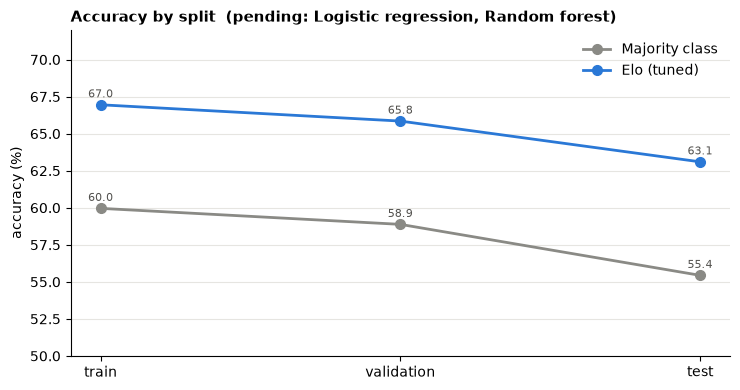

In [2]:
done = results.dropna(subset=["accuracy"])
done_models = list(dict.fromkeys(done["model"]))
colors = ["#8a8a85", "#2a78d6", "#eb6834", "#1baf7a"]   # one fixed color per model, in table order

fig, ax = plt.subplots(figsize=(7.5, 4))
for m in done_models:
    color = colors[models.index(m)]
    vals = [done[(done["model"] == m) & (done["split"] == s)]["accuracy"].iloc[0] * 100 for s in splits]
    ax.plot(splits, vals, color=color, lw=2, marker="o", ms=7, label=m)
    for x, v in zip(splits, vals):
        ax.text(x, v + 0.5, f"{v:.1f}", ha="center", fontsize=8, color="#52514e")
ax.set_ylim(50, 72); ax.set_ylabel("accuracy (%)")
ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", color="#e6e5e1")
ax.legend(frameon=False, loc="upper right")
pending = [m for m in models if m not in done_models]
ax.set_title("Accuracy by split" + (f"  (pending: {', '.join(pending)})" if pending else ""), loc="left", fontweight="bold", fontsize=11)
plt.tight_layout(); plt.show()

### Step 3: findings so far

**Majority class (notebook 03)**
- Always predicts a home win. Accuracy is exactly the home win rate of each period: 59.96% train, 58.88% validation, 55.44% test.
- Recall is 1.0 and precision equals accuracy because it never predicts an away win. ROC-AUC is 0.5 because every game gets the same probability, so it cannot rank games.
- Fit: it learns one number, so it cannot overfit or underfit in a useful sense. It is the floor every model must beat.
- Test is lower only because the home win rate fell to about 55% in the COVID seasons (2019-2021).

**Elo rating (notebook 04)**
- About 7 points above the majority class on every split: 66.95% train, 65.85% validation, 63.10% test (ROC-AUC 0.71 / 0.70 / 0.67).
- Tuned with forward-chaining folds (2012-2016): K = 20, home advantage = 75, carryover = 0.75. Tuning barely matters: the default setting is only 0.3 to 0.9 points worse, and the scores change more between seasons than between settings.
- Fit: **no overfitting**. Train and validation are close (66.95% vs 65.85%, log loss 0.6052 vs 0.6182). With 3 settings it cannot memorize the data.
- If anything it **underfits**: one strength number per team cannot use rest days or recent form.
- On test it over-predicts home wins (the calibration plot falls below the diagonal), because the COVID seasons had a weaker home edge than Elo expects.

**Logistic regression (notebook 05)**: *to add when the notebook is done.*

**Random forest (notebook 06)**: *to add when the notebook is done.*

### Step 4: proposed fixes for overfitting / underfitting
*To add after the logistic regression and random forest results are in.*